## ProShares VIX Mid-Term Futures ETF

In [1]:
import os
import sys
import requests
import datetime as dt
import numpy as np
from dotenv import load_dotenv
from pathlib import Path
import requests
import pandas as pd
import talib as ta
import plotly.graph_objs as go

import ipywidgets as widgets
from ipywidgets import Dropdown, Text, Button, Output
from IPython.display import display

from Modules.utility import Utility
from Modules.show_plot import ShowPlot
from Modules.reques_api import RequestApi
from Modules.get_market_data import GetMarketData
from Modules.stock_prices_and_market_data import ClassStockPricesMarketData
from Modules.financial import Financial
from Modules.pdf_url_to_markdown import PDFUrlToMarkdown
from Modules.webpage_to_markdown import WebpageToMarkdown
from Modules.compute_fibonacci_extension import ComputeFibonacciExtension

In [2]:
API_BASE_URL = os.getenv("API_BASE_URL", "http://localhost:8000")
request_api = RequestApi(API_BASE_URL)
get_market_data = GetMarketData(Path('/workspace/data'))
utility = Utility()
stock_prices_market_data = ClassStockPricesMarketData()
financial = Financial()
# URLからPDFをダウンロードしてMarkdownに変換するクラスのインスタンスを作成
pdf_to_md = PDFUrlToMarkdown()
# WEBページをMarkdownに変換する関数
webpage_to_markdown = WebpageToMarkdown()
# Fibonacciエクステンションを計算するクラスのインスタンスを作成
fibonacci_extension = ComputeFibonacciExtension()

In [3]:
start = '1999-01-01'
end = dt.datetime.now().strftime('%Y-%m-%d')

#### VIX指数の時系列データを取得

In [4]:
vix = '^VIX'
market = None

response = request_api.update_stock_timeseries_data(
    code=vix,
    market=market,
    start=start,
    end=end
)
response

{'result': True}

In [5]:
vix_timeseries_df = request_api.get_stock_time_series_data(
    code=vix,
    market=market,
    start=start,
    end=end
)
vix_timeseries_df

取得件数: 7023


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,1278457,^VIX,None,1998-11-17,27.950001,30.559999,27.209999,29.340000,0,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,1278458,^VIX,None,1998-11-18,27.129999,28.459999,27.129999,28.129999,0,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,1278459,^VIX,None,1998-11-19,25.500000,26.400000,25.309999,26.100000,0,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,1278460,^VIX,None,1998-11-20,22.469999,24.010000,22.430000,24.010000,0,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,1278461,^VIX,None,1998-11-23,21.840000,22.230000,21.240000,22.200001,0,25.956,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7018,1285475,^VIX,None,2026-10-12,15.210000,15.530000,15.110000,15.390000,0,15.424,...,15.063017,10.249296,False,NaN,NaN,NaN,NaN,NaN,NaN,False
7019,1285476,^VIX,None,2026-10-13,15.270000,15.610000,15.170000,15.610000,0,15.446,...,15.065767,14.889439,False,NaN,NaN,NaN,NaN,NaN,NaN,False
7020,1285477,^VIX,None,2026-10-14,16.870001,17.450001,14.980000,15.170000,0,15.438,...,15.035599,14.868095,False,NaN,NaN,NaN,NaN,NaN,NaN,False
7021,1285478,^VIX,None,2026-10-15,16.459999,18.010000,16.340000,17.549999,0,15.812,...,15.026890,21.407837,False,NaN,NaN,0.0499,NaN,-5.0,NaN,False


#### VIXMの時系列データを取得

In [6]:
vixm = 'VIXM'
market = None

response = request_api.update_stock_timeseries_data(
    code=vixm,
    market=market,
    start=start,
    end=end
)
response

{'result': True}

In [7]:
vixm_timeseries_df = request_api.get_stock_time_series_data(
    code=vixm,
    market=market,
    start=start,
    end=end
)
vixm_timeseries_df

取得件数: 3970


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,1285480,VIXM,None,2011-01-04,318.480011,320.839996,318.480011,318.480011,26800,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,1285481,VIXM,None,2011-01-05,313.640015,318.640015,312.600006,318.640015,2125,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,1285482,VIXM,None,2011-01-06,314.239990,314.239990,311.600006,312.519989,2275,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,1285483,VIXM,None,2011-01-07,314.920013,314.920013,311.920013,311.920013,2700,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,1285484,VIXM,None,2011-01-10,314.040009,318.079987,313.519989,318.079987,500,315.928003,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3965,1289445,VIXM,None,2026-10-12,12.720000,12.840000,12.710000,12.840000,121400,12.792000,...,12.816759,-96.068471,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3966,1289446,VIXM,None,2026-10-13,12.680000,12.720000,12.660000,12.680000,88200,12.774000,...,12.787038,-96.222146,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3967,1289447,VIXM,None,2026-10-14,12.720000,12.830000,12.700000,12.800000,355200,12.764000,...,12.772585,-95.978827,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3968,1289448,VIXM,None,2026-10-15,12.710000,12.930000,12.690000,12.930000,198100,12.810000,...,12.771356,-94.685392,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### チャート

In [8]:
def stock_prices_and_index(
        code: str,
        name: str,
        start: str,
        end: str,
        market: str | None = None,
        df_sp: pd.DataFrame | None = None,
        index_name: str | None = None,
        df_index: pd.DataFrame | None = None,
    ):
    # /api/v1/time_series_data/stock/
    response = request_api.get_stock_time_series_data(
        code=code,
        market=market,
        start=start,
        end=end
    )
    df_stock = pd.DataFrame(response)

    # S&P500を統合
    if df_sp is not None:
        df_sp_tmp = df_sp.copy() if df_sp is not None else pd.DataFrame()
        if "date" not in df_sp_tmp.columns:
            df_sp_tmp = df_sp_tmp.reset_index()

        df_sp_tmp["date"] = pd.to_datetime(df_sp_tmp["date"])
        df_sp_tmp = df_sp_tmp.set_index("date")
        df_sp_tmp = df_sp_tmp.loc[start:end]

    # INDEXを統合
    if df_index is not None:
        df_index_tmp = df_index.copy() if df_index is not None else pd.DataFrame()
        if "date" not in df_index_tmp.columns:
            df_index_tmp = df_index_tmp.reset_index()
        df_index_tmp["date"] = pd.to_datetime(df_index_tmp["date"])
        df_index_tmp = df_index_tmp.set_index("date")
        df_index_tmp = df_index_tmp.loc[start:end]

    # 株価時系列データを整形
    df = df_stock.copy()
    df["date"] = pd.to_datetime(df["date"])
    df = df.set_index("date")
    df = df.loc[start:end]


    # インデックスを揃えて結合
    if df_sp is not None:
        df["MA50_SP"] = df_sp_tmp["ma50"].reindex(df.index)
        df["MA200_SP"] = df_sp_tmp["ma200"].reindex(df.index)
    if df_index is not None:
        df["MA50_" + index_name] = df_index_tmp["ma50"].reindex(df.index)
        df["MA200_" + index_name] = df_index_tmp["ma200"].reindex(df.index)

    show_plot = ShowPlot()
    fig = show_plot.create_basic_chart(
        df=df.reset_index(),
        code=code,
        name=name,
        start=start,
        end=end,
        ma5=False,
        ma25=False,
        ma50=True,
        ma100=False,
        ma150=False,
        ma200=True,
    )
    # ★ 2つのY軸を定義（左：HYMC、右：SP500 & GOLD）
    fig.update_layout(
        yaxis=dict(
            title=f"{name} Price",
            side="left"
        ),
        yaxis2=dict(
            title="SP500 / WTI",
            overlaying="y",
            side="right"
        )
    )

    # --- SP500（右軸） ---
    if df_sp is not None:
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA50_SP"],
                name="SP_MA50",
                line={"color": "blue", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA200_SP"],
                name="SP_MA200",
                line={"color": "gray", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )

    # --- INDEX（右軸） ---
    if df_index is not None:
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA50_" + index_name],
                name=index_name + "_MA50",
                line={"color": "orange", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA200_" + index_name],
                name=index_name + "_MA200",
                line={"color": "yellow", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )

    return fig

#### VIXMのチャート

In [9]:
name = "ProShares VIX Mid-Term Futures ETF"
start = dt.datetime(2025, 1, 1).strftime("%Y-%m-%d")
# グラフ領域の作成
fig = stock_prices_and_index(
    code=vixm,
    name=name,
    start=start,
    end=end,
    market=None,
    df_sp=None,
    df_index=None
)
fig.show()

取得件数: 656


In [10]:
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"{vixm}_{start}_{end}.png"
# 既存の画像ファイルが存在する場合は削除
if output_path.exists():
    output_path.unlink()
# 画像ファイルを保存
fig.write_image(str(output_path), width=1600, height=900, scale=2)
# 保存完了のメッセージを表示
print("saved:", output_path)

saved: /workspace/data/figures/VIXM_2025-01-01_2026-10-17.png


#### VIX指数のチャート

In [11]:
name = "CBOE Volatility Index (^VIX)"
start = dt.datetime(2025, 1, 1).strftime("%Y-%m-%d")
# グラフ領域の作成
fig = stock_prices_and_index(
    code=vix,
    name=name,
    start=start,
    end=end,
    market=None,
    df_sp=None,
    df_index=None
)
fig.show()

取得件数: 658


In [12]:
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"{vix}_{start}_{end}.png"
# 既存の画像ファイルが存在する場合は削除
if output_path.exists():
    output_path.unlink()
# 画像ファイルを保存
fig.write_image(str(output_path), width=1600, height=900, scale=2)
# 保存完了のメッセージを表示
print("saved:", output_path)

saved: /workspace/data/figures/^VIX_2025-01-01_2026-10-17.png


#### 時系列データを保存

In [13]:
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"{vixm}_data_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 既存の CSV ファイルが存在する場合は削除
if output_path.exists():
    output_path.unlink()
# CSV ファイルを新規作成する準備完了
vixm_df = vixm_timeseries_df.copy()
vixm_df = vixm_df.reset_index()
vixm_df["date"] = pd.to_datetime(vixm_df["date"])
vixm_df = vixm_df.set_index("date")
vixm_df = vixm_df.loc['2026-01-01':end]
vixm_df.to_csv(output_path)
vixm_df.head()

,index,id,stock_code,stock_market,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
date,,,,,,,,,,,,,,,,,,,,,
2026-01-02,3771,1289251,VIXM,None,15.20,15.24,15.11,15.11,233400,15.108,...,15.148574,-62.661146,False,NaN,NaN,NaN,NaN,NaN,NaN,True
2026-01-05,3772,1289252,VIXM,None,15.20,15.24,15.09,15.13,236300,15.132,...,15.122467,-65.333390,False,NaN,NaN,-0.275648,NaN,NaN,NaN,False
2026-01-06,3773,1289253,VIXM,None,15.17,15.23,15.14,15.23,275600,15.138,...,15.105368,-68.586186,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-07,3774,1289254,VIXM,None,15.27,15.31,15.17,15.19,141900,15.154,...,15.096186,-71.241356,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-08,3775,1289255,VIXM,None,15.13,15.31,15.09,15.31,299100,15.194,...,15.086379,-73.187911,False,NaN,NaN,NaN,NaN,NaN,NaN,False


In [14]:
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"{vix}_data_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 既存の CSV ファイルが存在する場合は削除
if output_path.exists():
    output_path.unlink()
# CSV ファイルを新規作成する準備完了
vix_df = vix_timeseries_df.copy()
vix_df = vix_df.reset_index()
vix_df["date"] = pd.to_datetime(vix_df["date"])
vix_df = vix_df.set_index("date")
vix_df = vix_df.loc['2026-01-01':end]
vix_df.to_csv(output_path)
vix_df.head()

,index,id,stock_code,stock_market,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
date,,,,,,,,,,,,,,,,,,,,,
2026-01-02,6822,1285279,^VIX,None,14.51,15.42,14.46,14.85,0,14.572,...,14.787274,-54.729787,False,NaN,NaN,NaN,NaN,NaN,NaN,True
2026-01-05,6823,1285280,^VIX,None,14.90,15.27,14.65,15.14,0,14.776,...,14.735110,-55.814053,False,NaN,NaN,-0.92754,NaN,NaN,NaN,False
2026-01-06,6824,1285281,^VIX,None,14.75,15.21,14.63,15.00,0,14.838,...,14.665879,-57.222744,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-07,6825,1285282,^VIX,None,15.38,15.48,14.83,14.95,0,14.942,...,14.623412,-59.442500,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-08,6826,1285283,^VIX,None,15.45,15.85,15.15,15.69,0,15.126,...,14.608978,-60.035858,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### フィボナッチエクステンション

{'fib_levels_down': {'1.000': np.float64(12.640000343322754),
  '1.272': np.float64(11.690720664978027),
  '1.382': np.float64(11.306820795059204),
  '1.618': np.float64(10.483181074142456)},
 'fib_levels_up': {'1.272': np.float64(17.07927883911133),
  '1.382': np.float64(17.463178709030153),
  '1.618': np.float64(18.286818429946898),
  '2.000': np.float64(19.61999797821045)},
 'swing_high': np.float64(16.1299991607666),
 'swing_low': np.float64(12.640000343322754),
 'df_with_fib':           date  index       id stock_code stock_market   open   high    low  \
 0   2026-01-02   3771  1289251       VIXM         None  15.20  15.24  15.11   
 1   2026-01-05   3772  1289252       VIXM         None  15.20  15.24  15.09   
 2   2026-01-06   3773  1289253       VIXM         None  15.17  15.23  15.14   
 3   2026-01-07   3774  1289254       VIXM         None  15.27  15.31  15.17   
 4   2026-01-08   3775  1289255       VIXM         None  15.13  15.31  15.09   
 ..         ...    ...      ...   

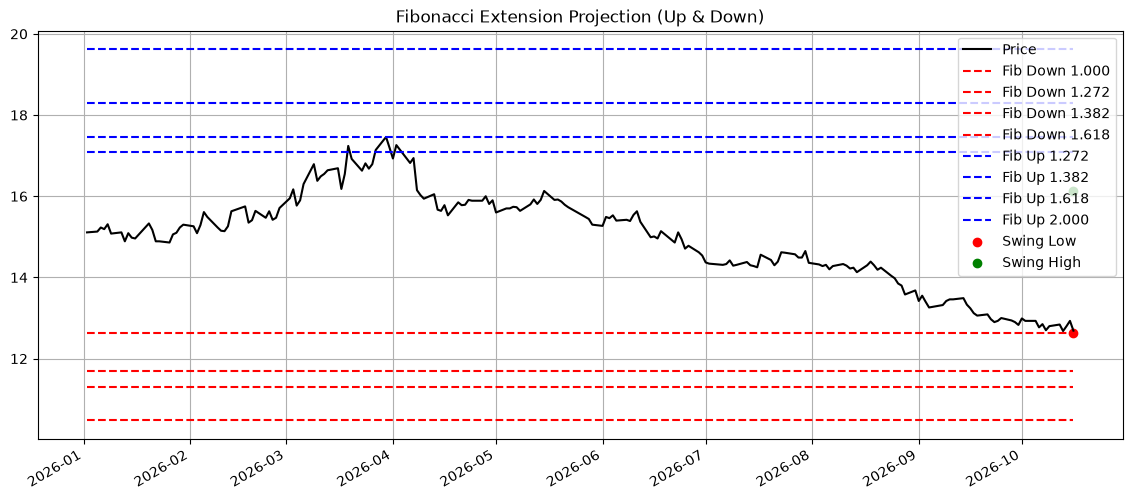

In [15]:
fib_result = fibonacci_extension.compute_fibonacci_extension(vixm_df.copy().reset_index())
fib_result

In [16]:
output_dir = Path("/workspace/data/figures/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"{vixm}_fibonacci_extension_{dt.datetime.now().strftime('%Y-%m-%d')}.png"
# 既存の画像ファイルが存在する場合は削除
if output_path.exists():
    output_path.unlink()
# 画像ファイルを保存
fib_result["plot_obj"].savefig(output_path, dpi=300, bbox_inches="tight")
print("saved:", output_path)

saved: /workspace/data/figures/VIXM_fibonacci_extension_2026-10-17.png


{'fib_levels_down': {'1.000': np.float64(13.800000190734863),
  '1.272': np.float64(11.205120201110839),
  '1.382': np.float64(10.155720205307006),
  '1.618': np.float64(7.904280214309693)},
 'fib_levels_up': {'1.272': np.float64(25.934880142211913),
  '1.382': np.float64(26.984280138015748),
  '1.618': np.float64(29.23572012901306),
  '2.000': np.float64(32.88000011444092)},
 'swing_high': np.float64(23.34000015258789),
 'swing_low': np.float64(13.800000190734863),
 'df_with_fib':           date  index       id stock_code stock_market       open       high  \
 0   2026-01-02   6822  1285279       ^VIX         None  14.510000  15.420000   
 1   2026-01-05   6823  1285280       ^VIX         None  14.900000  15.270000   
 2   2026-01-06   6824  1285281       ^VIX         None  14.750000  15.210000   
 3   2026-01-07   6825  1285282       ^VIX         None  15.380000  15.480000   
 4   2026-01-08   6826  1285283       ^VIX         None  15.450000  15.850000   
 ..         ...    ...      

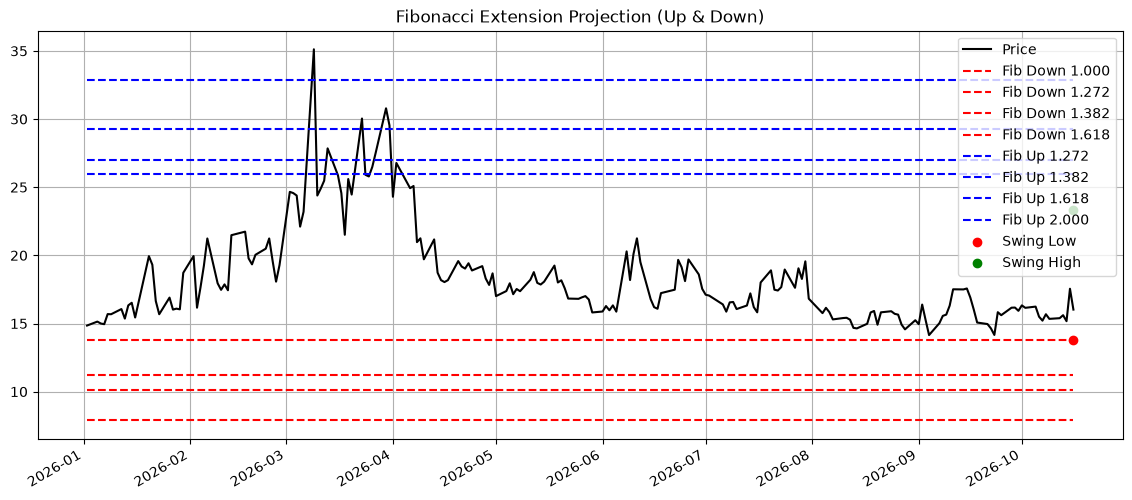

In [17]:
fib_result = fibonacci_extension.compute_fibonacci_extension(vix_df.copy().reset_index())
fib_result

In [18]:
output_dir = Path("/workspace/data/figures/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"{vix}_fibonacci_extension_{dt.datetime.now().strftime('%Y-%m-%d')}.png"
# 既存の画像ファイルが存在する場合は削除
if output_path.exists():
    output_path.unlink()
# 画像ファイルを保存
fib_result["plot_obj"].savefig(output_path, dpi=300, bbox_inches="tight")
print("saved:", output_path)

saved: /workspace/data/figures/^VIX_fibonacci_extension_2026-10-17.png
